## Step 1 — Problem framing and theory

### 1. What is customer churn and why does it matter?
- **Churn** occurs when a paying subscriber stops using or paying for a service.
- Predicting churn helps a retention team contact at-risk customers before they leave and prioritize limited outreach capacity.
- Acquiring a replacement customer costs money (**CAC**, Customer Acquisition Cost); retaining a customer can preserve future revenue and **CLV**, Customer Lifetime Value.

### 2. Confusion matrix and business costs
- **TP:** churner correctly flagged; the team can offer a retention action.
- **TN:** retained customer correctly identified; no unnecessary intervention.
- **FP:** retained customer incorrectly flagged; outreach costs time and may require an unnecessary discount.
- **FN:** actual churner missed by the model; the company loses a chance to retain revenue. In this use case, FN can be especially costly.

### 3. Class imbalance and SMOTE
- Class imbalance means one target class occurs much more often than the other.
- The dataset is imbalanced: roughly 27% churn and 73% non-churn, so accuracy alone can be misleading.
- SMOTE creates synthetic minority-class training examples by interpolating between nearby minority observations. It must be applied only to training data.

### 4. Four supervised algorithms
- **KNN:** classifies a customer using the labels of the nearest training examples; feature scaling matters because distances drive predictions.
- **Gaussian Naive Bayes:** applies Bayes’ theorem and models each feature within each class with a Gaussian distribution; it assumes conditional feature independence.
- **SVM:** finds a separating boundary with a large margin; an RBF kernel can model nonlinear boundaries. Scaling is important.
- **Decision Tree:** recursively splits features to improve class separation; it is interpretable but can overfit without depth/leaf constraints.

### 5. When is precision more important than recall?
- Precision matters when retention offers are expensive or outreach capacity is very limited, because it measures how many flagged customers actually churn.
- Recall is the priority when missing a genuine churner is more costly. The practical choice should balance both against the team's daily capacity.

In [16]:
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, roc_curve
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

candidates = [
    Path("WA_Fn-UseC_-Telco-Customer-Churn.csv"),
    Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv"),
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Download WA_Fn-UseC_-Telco-Customer-Churn.csv "
        "from https://www.kaggle.com/datasets/blastchar/telco-customer-churn "
        "and put it beside this notebook or inside data/."
    )

df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
df_raw.info()
display(df_raw.describe(include="all").T)
display(df_raw.head(10))

Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 n

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


## Step 2 — Data inspection and EDA

In [17]:
df = df_raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")
print("Blank/invalid TotalCharges:", int(df["TotalCharges"].isna().sum()))
print("Rows with missing TotalCharges and tenure:")
display(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges"]].head(15))

print("\\nTarget counts:")
display(df["Churn"].value_counts().rename("count").to_frame())
display((df["Churn"].value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())
print("Churn rate (%):", round((df["Churn"] == "Yes").mean() * 100, 2))

Blank/invalid TotalCharges: 11
Rows with missing TotalCharges and tenure:


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


\nTarget counts:


,count
Churn,
No,5174
Yes,1869


,percent
Churn,
No,73.46
Yes,26.54


Churn rate (%): 26.54


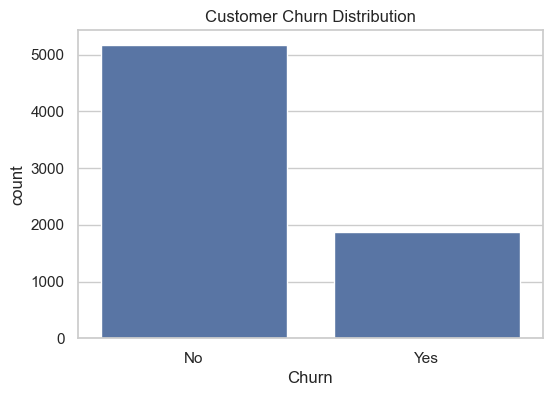

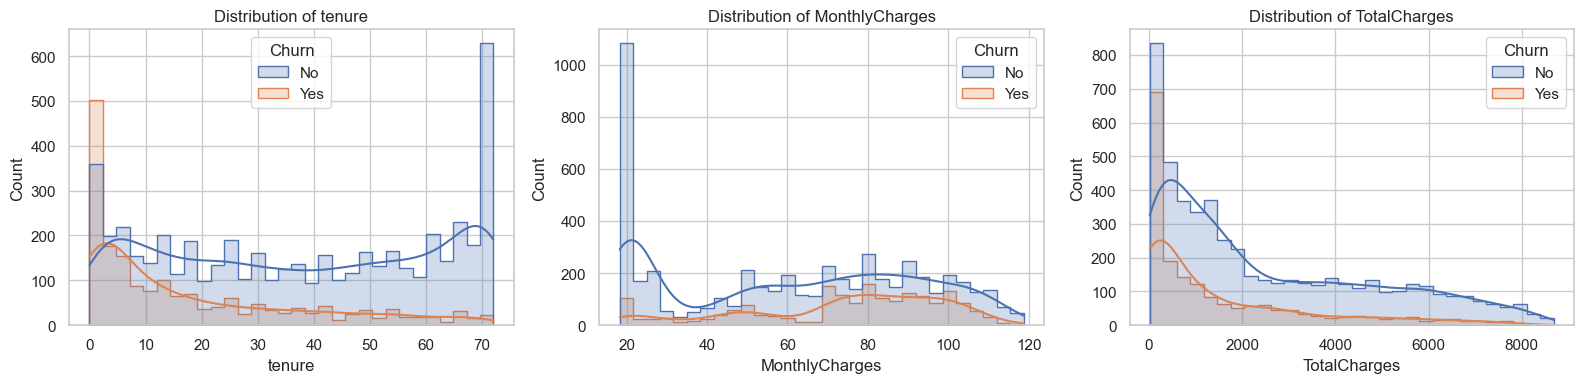

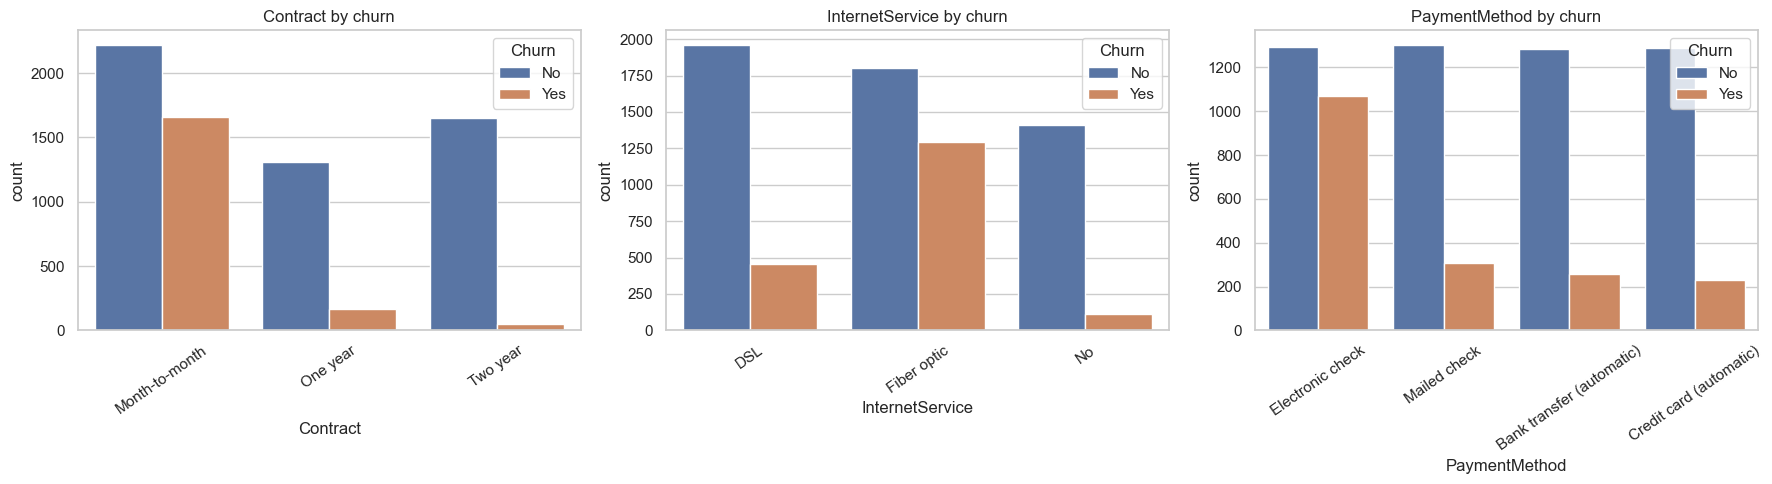

In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Churn", ax=ax)
ax.set_title("Customer Churn Distribution")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for col, ax in zip(["tenure", "MonthlyCharges", "TotalCharges"], axes):
    sns.histplot(data=df, x=col, hue="Churn", bins=30, kde=True, ax=ax, element="step")
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for col, ax in zip(["Contract", "InternetService", "PaymentMethod"], axes):
    sns.countplot(data=df, x=col, hue="Churn", ax=ax)
    ax.tick_params(axis="x", rotation=35)
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.show()

,churn_rate_percent
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


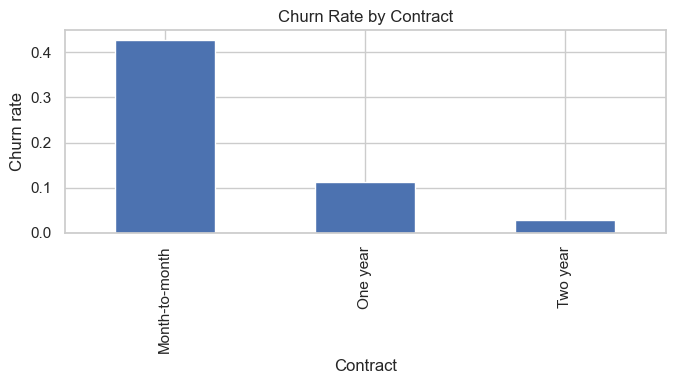

,churn_rate_percent
tenure_bucket,
0-12,47.44
13-24,28.71
25-48,20.39
49-72,9.51


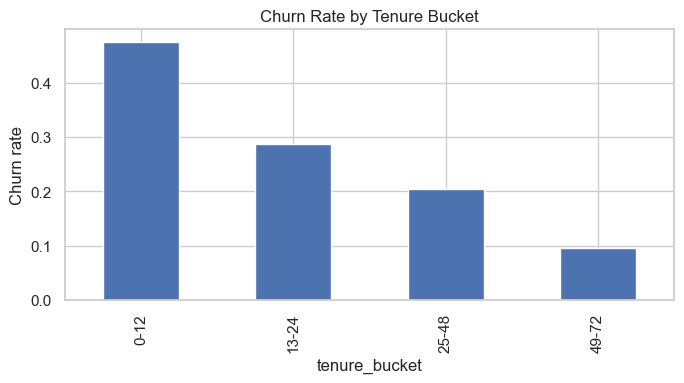

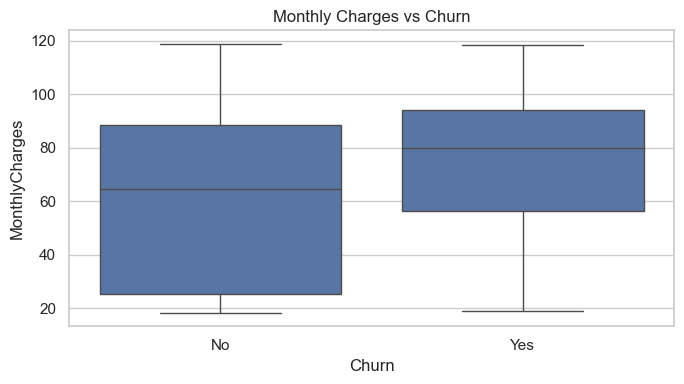

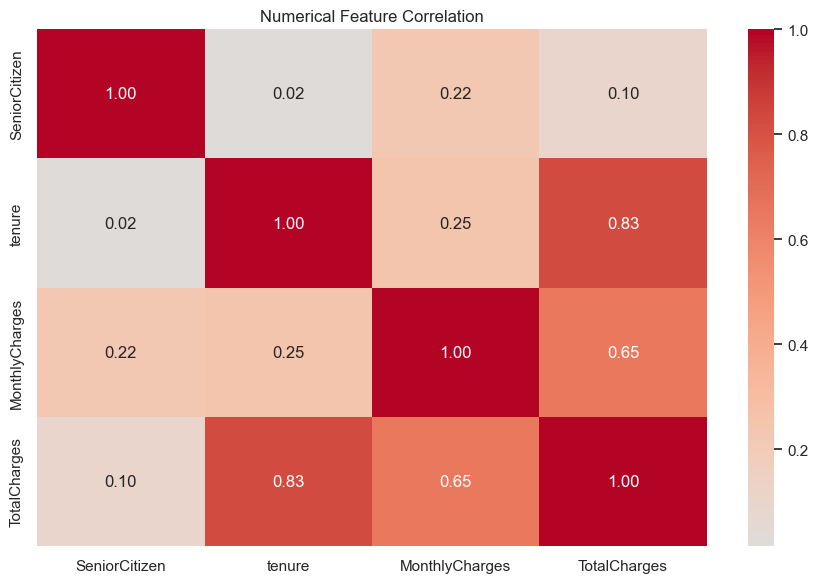

In [19]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index")["Yes"].sort_values(ascending=False)
display((contract_churn * 100).round(2).rename("churn_rate_percent").to_frame())
contract_churn.plot(kind="bar", figsize=(7, 4), title="Churn Rate by Contract")
plt.ylabel("Churn rate")
plt.tight_layout()
plt.show()

df["tenure_bucket"] = pd.cut(
    df["tenure"], bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"], include_lowest=True
)
tenure_churn = df.groupby("tenure_bucket", observed=False)["Churn"].apply(lambda s: (s == "Yes").mean())
display((tenure_churn * 100).round(2).rename("churn_rate_percent").to_frame())
tenure_churn.plot(kind="bar", figsize=(7, 4), title="Churn Rate by Tenure Bucket")
plt.ylabel("Churn rate")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.tight_layout()
plt.show()

numeric = df.select_dtypes(include=np.number)
plt.figure(figsize=(9, 6))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numerical Feature Correlation")
plt.tight_layout()
plt.show()

## Step 3 — Cleaning, feature engineering, encoding and split

The 11 blank `TotalCharges` values are converted to missing numeric values and imputed with the median as specified. The target is encoded as 1 = churn and 0 = retained. We use a preprocessing transformer so imputers/scalers/encoders are fit on training data only. SMOTE is also inside the training pipeline, preventing test-set contamination.

In [20]:
# Feature engineering before splitting uses only each row's own raw fields.
work = df_raw.copy()
work["TotalCharges"] = pd.to_numeric(work["TotalCharges"].astype(str).str.strip(), errors="coerce")
work["tenure_group"] = pd.cut(
    work["tenure"],
    bins=[-1, 12, 36, 60, np.inf],
    labels=["New", "Mid", "Senior", "Loyal"],
    include_lowest=True,
    ordered=True
).astype("object")

service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
work["num_services"] = work[service_cols].eq("Yes").sum(axis=1)
work["AutoPay"] = work["PaymentMethod"].str.contains("automatic", case=False, na=False).astype(int)
work["Churn"] = work["Churn"].map({"No": 0, "Yes": 1})
work = work.drop(columns=["customerID", "tenure_bucket"] + service_cols, errors="ignore")

# Fill TotalCharges with the training-set median through the numeric imputer, not before splitting.
X = work.drop(columns="Churn")
y = work["Churn"].astype(int)

numeric_features = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "num_services", "AutoPay"]
binary_features = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]
categorical_features = ["gender", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                        "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
                        "Contract", "PaymentMethod", "tenure_group"]
# Drop any accidental placeholder if absent; keep available feature columns only.
categorical_features = [c for c in categorical_features if c in X.columns]
binary_features = [c for c in binary_features if c in X.columns]
numeric_features = [c for c in numeric_features if c in X.columns]

# Yes/No-style binary columns become 0/1; non-Yes/No values are handled by one-hot encoding instead.
for col in binary_features:
    X[col] = X[col].map({"Yes": 1, "No": 0})

# Remove binary fields from categorical lists if already mapped.
categorical_features = [c for c in categorical_features if c not in binary_features]

numeric_transformer = SkPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
binary_transformer = SkPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])
categorical_transformer = SkPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("binary", binary_transformer, binary_features),
    ("categorical", categorical_transformer, categorical_features)
], remainder="drop", verbose_feature_names_out=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)
print("Training class counts before SMOTE:")
display(y_train.value_counts().sort_index().rename(index={0:"No churn",1:"Churn"}).to_frame("count"))

X_train: (5634, 16) X_test: (1409, 16)
y_train: (5634,) y_test: (1409,)
Training class counts before SMOTE:


,count
Churn,
No churn,4139
Churn,1495


### Apply SMOTE to training data only

In [21]:
# Fit the preprocessor on training data and inspect transformed class counts after SMOTE.
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train_transformed, y_train)
print("Training class counts after SMOTE:")
display(pd.Series(y_train_smote).value_counts().sort_index().rename(index={0:"No churn",1:"Churn"}).to_frame("count"))
print("Test distribution remains original:")
display(y_test.value_counts().sort_index().rename(index={0:"No churn",1:"Churn"}).to_frame("count"))

Training class counts after SMOTE:


,count
Churn,
No churn,4139
Churn,4139


Test distribution remains original:


,count
Churn,
No churn,1035
Churn,374


## Step 4 — KNN and Gaussian Naive Bayes

,k,Validation F1
0,1,0.496100
1,3,0.546961
2,5,0.560526
3,7,0.555556
4,9,0.564885
5,11,0.583439
6,15,0.578554


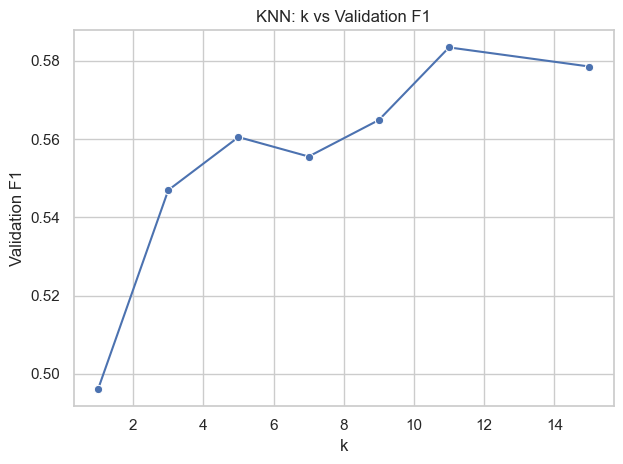

{'Model': 'KNN (k=11)', 'Accuracy': 0.7019162526614621, 'Precision': 0.4638364779874214, 'Recall': 0.7887700534759359, 'F1-Score': 0.5841584158415841, 'AUC-ROC': np.float64(0.8036528972590353)}


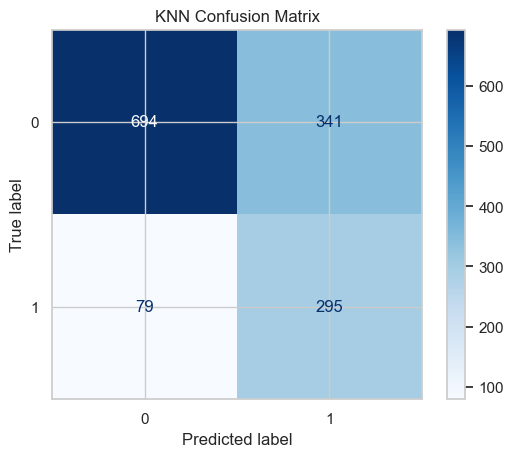

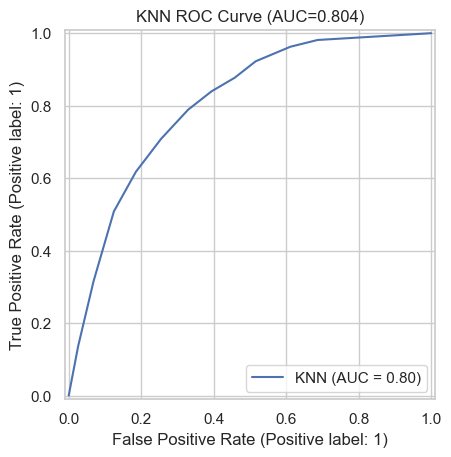

{'Model': 'Gaussian Naive Bayes', 'Accuracy': 0.7267565649396736, 'Precision': 0.4910277324632953, 'Recall': 0.8048128342245989, 'F1-Score': 0.6099290780141844, 'AUC-ROC': np.float64(0.8197499289570901)}
Learned class priors: [0.5 0.5]
Actual training churn rate before SMOTE: 0.2654


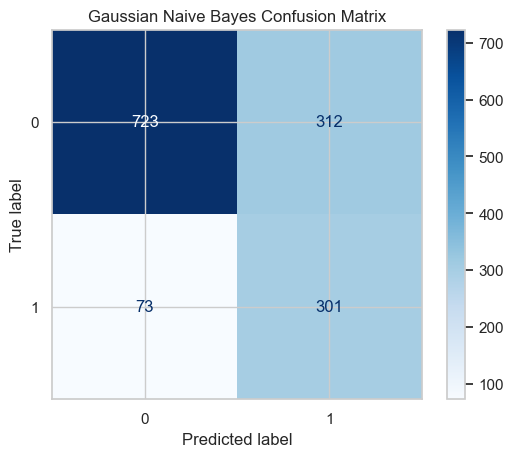

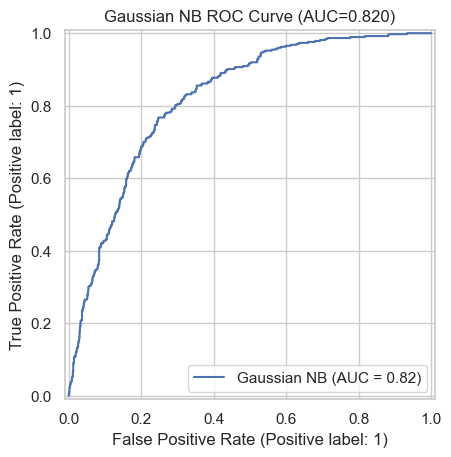

In [22]:
def evaluate_model(name, model, X_eval, y_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_eval)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1-Score": f1_score(y_eval, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_eval, prob),
        "y_pred": pred,
        "y_prob": prob
    }

# Tune K on a held-out validation split taken from the training partition.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_transformed, y_train, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train
)
X_fit_sm, y_fit_sm = SMOTE(random_state=RANDOM_STATE).fit_resample(X_fit, y_fit)
knn_scores = []
for k in [1, 3, 5, 7, 9, 11, 15]:
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_fit_sm, y_fit_sm)
    knn_scores.append((k, f1_score(y_val, m.predict(X_val), zero_division=0)))
knn_tuning = pd.DataFrame(knn_scores, columns=["k", "Validation F1"])
display(knn_tuning)
sns.lineplot(data=knn_tuning, x="k", y="Validation F1", marker="o")
plt.title("KNN: k vs Validation F1")
plt.tight_layout()
plt.show()

best_k = int(knn_tuning.sort_values("Validation F1", ascending=False).iloc[0]["k"])
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_smote, y_train_smote)
knn_result = evaluate_model(f"KNN (k={best_k})", knn, X_test_transformed, y_test)
print({k:v for k,v in knn_result.items() if k not in ["y_pred","y_prob"]})
ConfusionMatrixDisplay.from_predictions(y_test, knn_result["y_pred"], cmap="Blues")
plt.title("KNN Confusion Matrix")
plt.show()
RocCurveDisplay.from_predictions(y_test, knn_result["y_prob"], name="KNN")
plt.title(f"KNN ROC Curve (AUC={knn_result['AUC-ROC']:.3f})")
plt.show()

gnb = GaussianNB()
gnb.fit(X_train_smote, y_train_smote)
nb_result = evaluate_model("Gaussian Naive Bayes", gnb, X_test_transformed, y_test)
print({k:v for k,v in nb_result.items() if k not in ["y_pred","y_prob"]})
print("Learned class priors:", gnb.class_prior_)
print("Actual training churn rate before SMOTE:", round(y_train.mean(), 4))
ConfusionMatrixDisplay.from_predictions(y_test, nb_result["y_pred"], cmap="Blues")
plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.show()
RocCurveDisplay.from_predictions(y_test, nb_result["y_prob"], name="Gaussian NB")
plt.title(f"Gaussian NB ROC Curve (AUC={nb_result['AUC-ROC']:.3f})")
plt.show()

**Naive Bayes independence assumption:** The assumption is unlikely to hold fully because telecom services and billing choices can be related (for example, internet service and add-on services). Gaussian Naive Bayes can still be a useful fast baseline, but its probabilities and classification errors should be validated empirically.

## Step 5 — SVM and Decision Tree

{'Model': 'SVM (C=1)', 'Accuracy': 0.7480482611781405, 'Precision': 0.5170556552962298, 'Recall': 0.7700534759358288, 'F1-Score': 0.6186895810955961, 'AUC-ROC': np.float64(0.8207677801028186)}


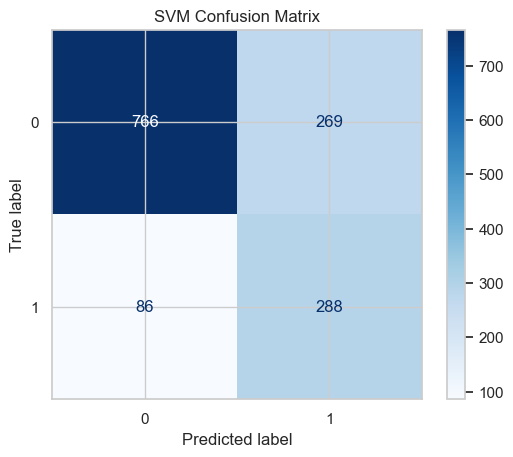

,C,Mean CV F1
0,0.1,0.625472
1,1.0,0.618929
2,10.0,0.593129
3,100.0,0.553826


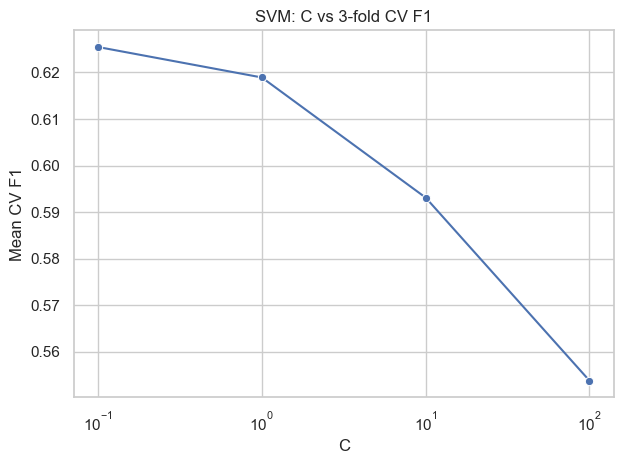

{'Model': 'SVM (C=0.1)', 'Accuracy': 0.7459190915542938, 'Precision': 0.5141342756183745, 'Recall': 0.7780748663101604, 'F1-Score': 0.6191489361702127, 'AUC-ROC': np.float64(0.8283732465318143)}


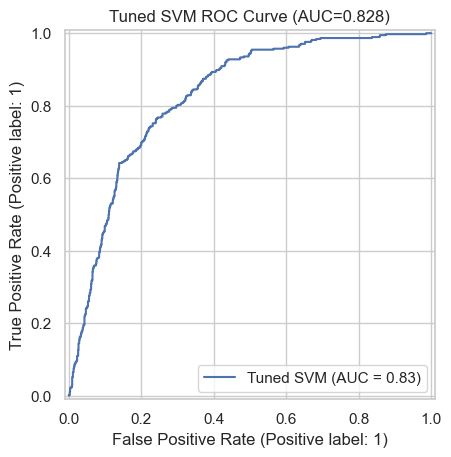

SVM tradeoff: An RBF SVM can capture nonlinear patterns, but it is less transparent than a small decision tree. For a regulated or customer-facing retention workflow, document the validation results and use explanations/monitoring alongside the score.


In [23]:
svm = SVC(kernel="rbf", C=1, gamma="scale", probability=True, random_state=RANDOM_STATE)
svm.fit(X_train_smote, y_train_smote)
svm_result = evaluate_model("SVM (C=1)", svm, X_test_transformed, y_test)
print({k:v for k,v in svm_result.items() if k not in ["y_pred","y_prob"]})
ConfusionMatrixDisplay.from_predictions(y_test, svm_result["y_pred"], cmap="Blues")
plt.title("SVM Confusion Matrix")
plt.show()

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
c_scores = []
for c in [0.1, 1, 10, 100]:
    estimator = ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", SVC(kernel="rbf", C=c, gamma="scale", class_weight=None, random_state=RANDOM_STATE))
    ])
    score = cross_val_score(estimator, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1).mean()
    c_scores.append((c, score))
svm_tuning = pd.DataFrame(c_scores, columns=["C", "Mean CV F1"])
display(svm_tuning)
sns.lineplot(data=svm_tuning, x="C", y="Mean CV F1", marker="o")
plt.xscale("log")
plt.title("SVM: C vs 3-fold CV F1")
plt.tight_layout()
plt.show()
best_c = float(svm_tuning.sort_values("Mean CV F1", ascending=False).iloc[0]["C"])
svm_best = SVC(kernel="rbf", C=best_c, gamma="scale", probability=True, random_state=RANDOM_STATE)
svm_best.fit(X_train_smote, y_train_smote)
svm_best_result = evaluate_model(f"SVM (C={best_c:g})", svm_best, X_test_transformed, y_test)
print({k:v for k,v in svm_best_result.items() if k not in ["y_pred","y_prob"]})
RocCurveDisplay.from_predictions(y_test, svm_best_result["y_prob"], name="Tuned SVM")
plt.title(f"Tuned SVM ROC Curve (AUC={svm_best_result['AUC-ROC']:.3f})")
plt.show()

print("SVM tradeoff: An RBF SVM can capture nonlinear patterns, but it is less transparent than a small decision tree. For a regulated or customer-facing retention workflow, document the validation results and use explanations/monitoring alongside the score.")

{'Model': 'Decision Tree (depth=5, balanced)', 'Accuracy': 0.752306600425834, 'Precision': 0.5214408233276158, 'Recall': 0.8128342245989305, 'F1-Score': 0.6353187042842215, 'AUC-ROC': np.float64(0.834511353948694)}


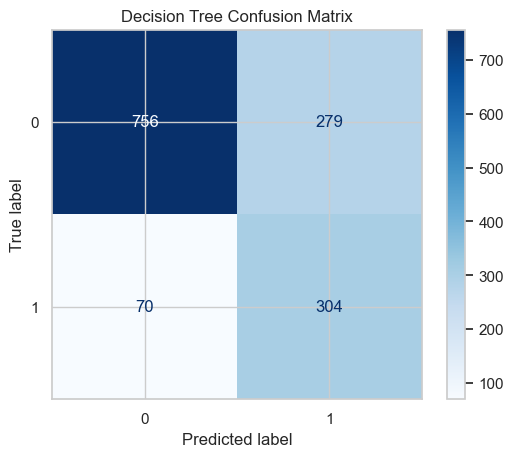

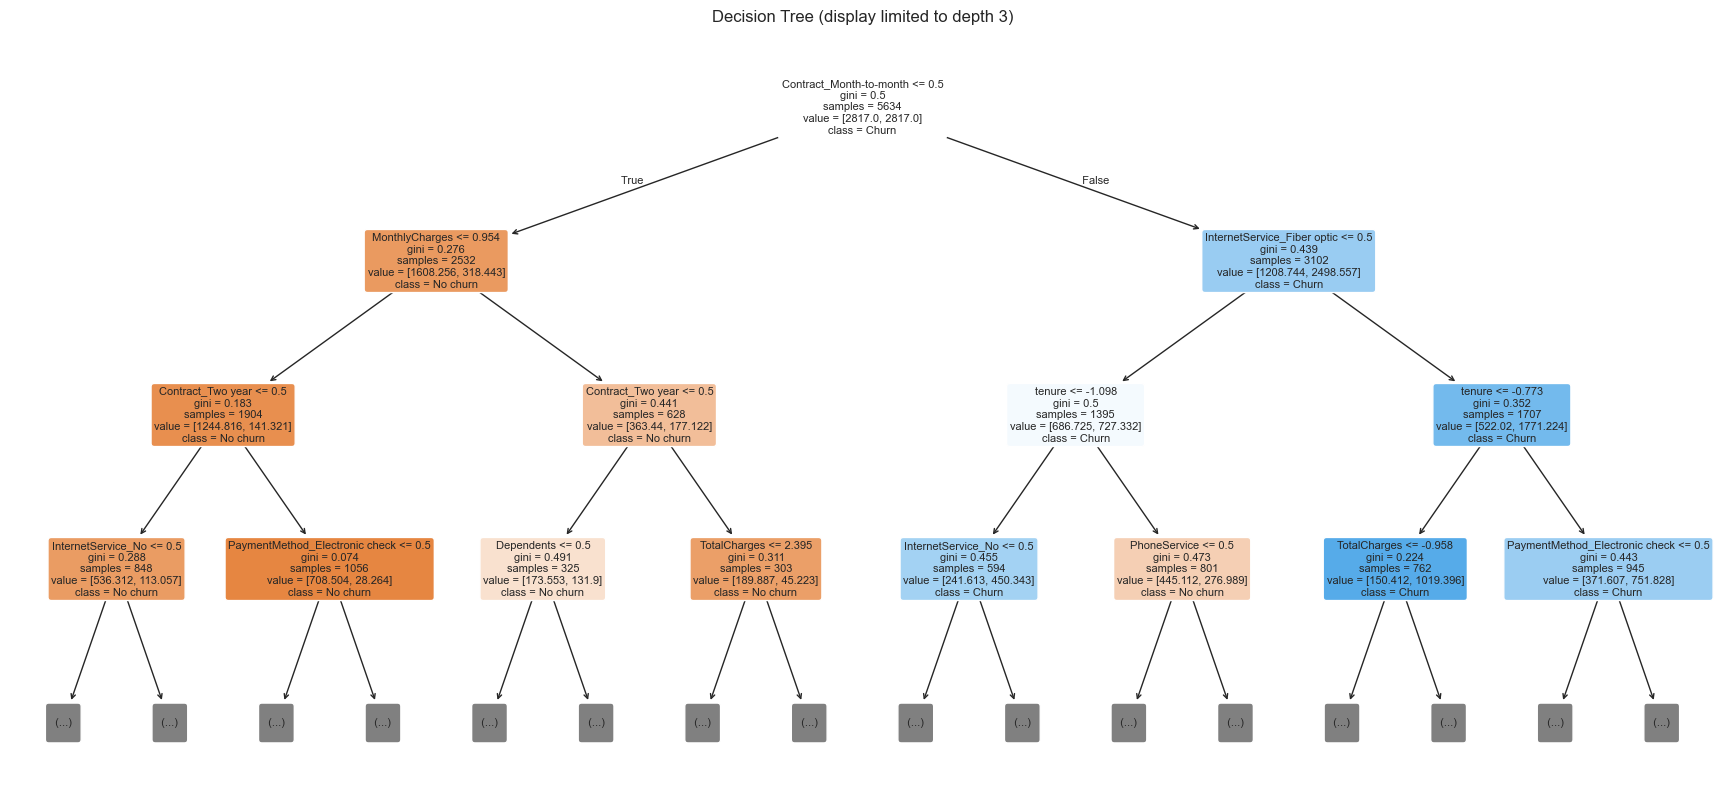

Root split feature: Contract_Month-to-month


,max_depth,Mean CV F1
0,3,0.619508
1,4,0.615491
2,5,0.608676
3,6,0.606864
4,7,0.607995
5,8,0.598672
6,None,0.487537


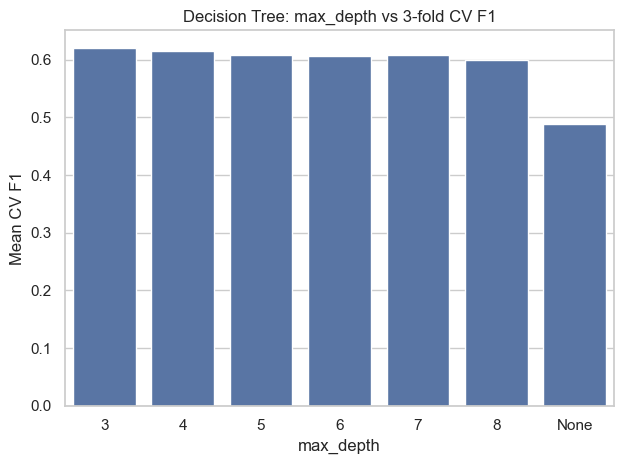

,importance
Contract_Month-to-month,0.699865
InternetService_Fiber optic,0.124223
tenure,0.103823
MonthlyCharges,0.042268
Contract_Two year,0.029821
AutoPay,0.000000
Partner,0.000000
Dependents,0.000000
PhoneService,0.000000
PaperlessBilling,0.000000


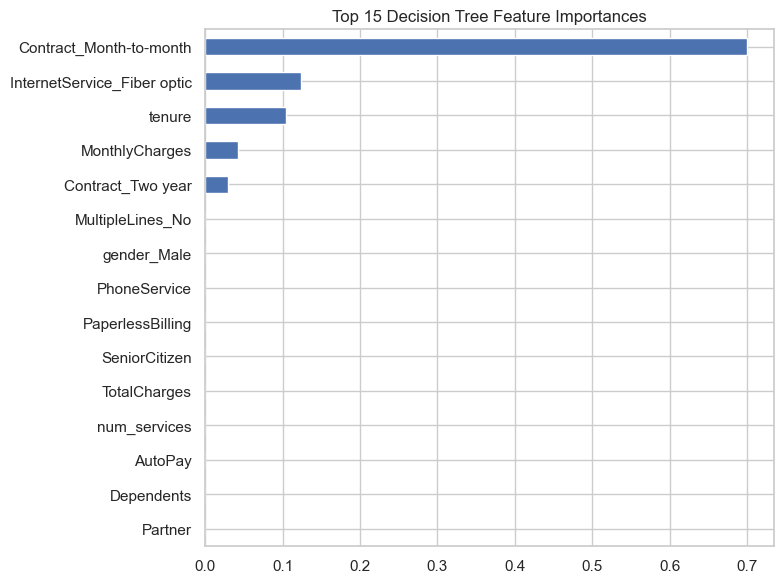

In [9]:
tree = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE)
tree.fit(X_train_transformed, y_train)
tree_result = evaluate_model("Decision Tree (depth=5, balanced)", tree, X_test_transformed, y_test)
print({k:v for k,v in tree_result.items() if k not in ["y_pred","y_prob"]})
ConfusionMatrixDisplay.from_predictions(y_test, tree_result["y_pred"], cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.show()

plt.figure(figsize=(22, 10))
plot_tree(tree, max_depth=3, feature_names=preprocessor.get_feature_names_out(),
          class_names=["No churn", "Churn"], filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree (display limited to depth 3)")
plt.show()
print("Root split feature:", preprocessor.get_feature_names_out()[tree.tree_.feature[0]])

depth_scores = []
for depth in [3, 4, 5, 6, 7, 8, None]:
    estimator = ImbPipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=RANDOM_STATE))
    ])
    score = cross_val_score(estimator, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1).mean()
    depth_scores.append(("None" if depth is None else str(depth), score))
depth_tuning = pd.DataFrame(depth_scores, columns=["max_depth", "Mean CV F1"])
display(depth_tuning)
sns.barplot(data=depth_tuning, x="max_depth", y="Mean CV F1")
plt.title("Decision Tree: max_depth vs 3-fold CV F1")
plt.tight_layout()
plt.show()

best_depth_label = depth_tuning.sort_values("Mean CV F1", ascending=False).iloc[0]["max_depth"]
best_depth = None if best_depth_label == "None" else int(best_depth_label)
tree_best = DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=RANDOM_STATE)
tree_best.fit(X_train_transformed, y_train)
tree_best_result = evaluate_model(f"Decision Tree (depth={best_depth})", tree_best, X_test_transformed, y_test)

importances = pd.Series(tree_best.feature_importances_, index=preprocessor.get_feature_names_out()).sort_values(ascending=False)
display(importances.head(15).rename("importance").to_frame())
importances.head(15).sort_values().plot(kind="barh", figsize=(8, 6), title="Top 15 Decision Tree Feature Importances")
plt.tight_layout()
plt.show()

### Compare SMOTE vs class_weight='balanced'

In [24]:
# Use the decision tree as the transparent comparison model.
tree_smote = DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE)
tree_smote.fit(X_train_smote, y_train_smote)
tree_weighted = DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=RANDOM_STATE)
tree_weighted.fit(X_train_transformed, y_train)
print("Recall with SMOTE:", round(recall_score(y_test, tree_smote.predict(X_test_transformed)), 4))
print("Recall with class_weight='balanced':", round(recall_score(y_test, tree_weighted.predict(X_test_transformed)), 4))

Recall with SMOTE: 0.7834
Recall with class_weight='balanced': 0.7834


## Step 6 — Consolidated model evaluation

,Model,Accuracy,Precision (Churn),Recall (Churn),F1-Score (Churn),AUC-ROC
0,Gaussian Naive Bayes,0.727,0.491,0.805,0.610,0.820
1,KNN tuned,0.702,0.464,0.789,0.584,0.804
2,Decision Tree tuned,0.746,0.514,0.783,0.621,0.816
3,SVM tuned,0.746,0.514,0.778,0.619,0.828


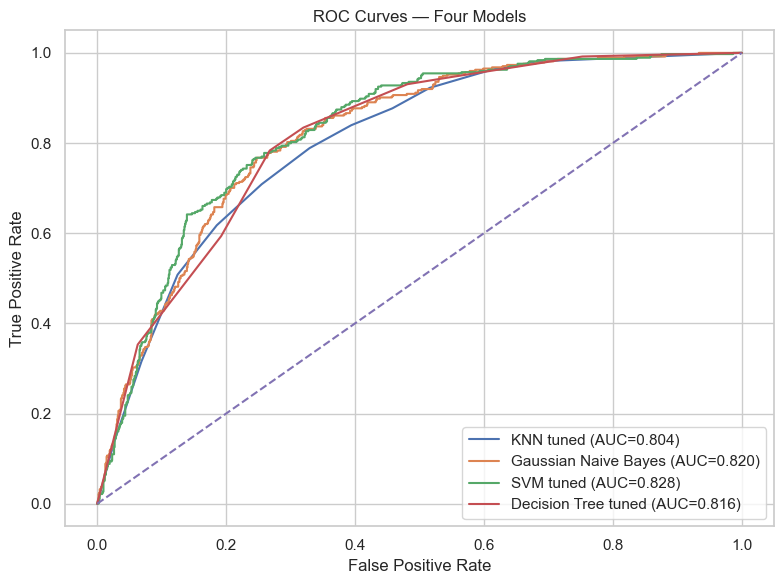

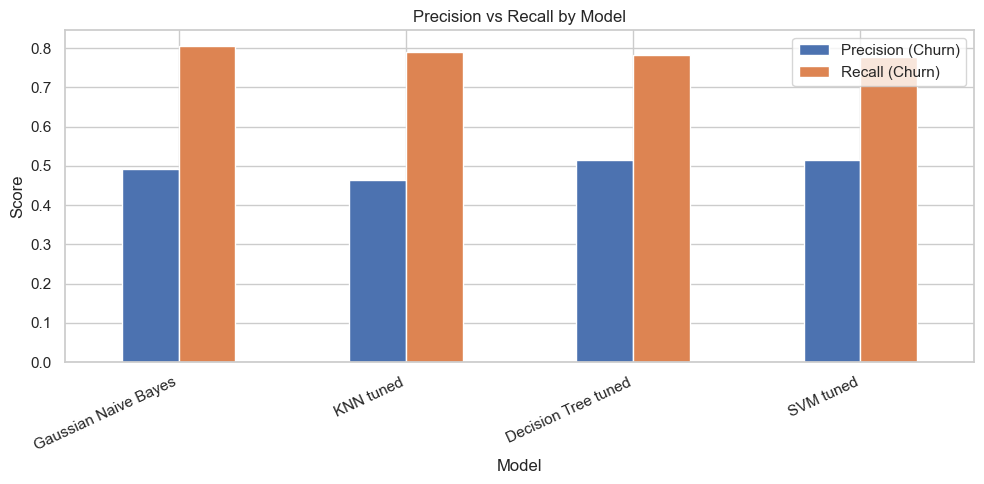

In [25]:
model_results = [
    ("KNN tuned", knn_result),
    ("Gaussian Naive Bayes", nb_result),
    ("SVM tuned", svm_best_result),
    ("Decision Tree tuned", tree_best_result)
]
comparison_rows = []
for name, result in model_results:
    comparison_rows.append({
        "Model": name,
        "Accuracy": result["Accuracy"],
        "Precision (Churn)": result["Precision"],
        "Recall (Churn)": result["Recall"],
        "F1-Score (Churn)": result["F1-Score"],
        "AUC-ROC": result["AUC-ROC"]
    })
comparison = pd.DataFrame(comparison_rows).sort_values("Recall (Churn)", ascending=False).reset_index(drop=True)
display(comparison.style.format({c:"{:.3f}" for c in comparison.columns if c != "Model"}))

plt.figure(figsize=(8, 6))
for name, result in model_results:
    fpr, tpr, _ = roc_curve(y_test, result["y_prob"])
    plt.plot(fpr, tpr, label=f"{name} (AUC={result['AUC-ROC']:.3f})")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Four Models")
plt.legend()
plt.tight_layout()
plt.show()

comparison.set_index("Model")[["Precision (Churn)", "Recall (Churn)"]].plot(kind="bar", figsize=(10, 5))
plt.title("Precision vs Recall by Model")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## Step 7 — Error analysis and business interpretation

In [26]:
# Choose the highest-recall candidate from the tested models.
best_name, best_result = max(model_results, key=lambda item: item[1]["Recall"])
best_pred = best_result["y_pred"]
test_profile = X_test.copy()
test_profile["actual_churn"] = y_test
test_profile["predicted_churn"] = best_pred
false_negatives = test_profile[(test_profile["actual_churn"] == 1) & (test_profile["predicted_churn"] == 0)]
actual_churners = test_profile[test_profile["actual_churn"] == 1]
print("Best by test recall:", best_name)
print("False negatives:", len(false_negatives))
display(false_negatives.head(20))
for label, subset in [("False negatives", false_negatives), ("All actual churners", actual_churners)]:
    print("\\n", label, "n =", len(subset))
    print("Average tenure:", subset["tenure"].mean())
    print("Average MonthlyCharges:", subset["MonthlyCharges"].mean())
    if "Contract" in subset:
        print("Contract distribution (%):")
        display((subset["Contract"].value_counts(normalize=True) * 100).round(1).to_frame("percent"))

print("Decision Tree top features:")
display(importances.head(5).rename("importance").to_frame())

Best by test recall: Gaussian Naive Bayes
False negatives: 73


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure_group,num_services,AutoPay,actual_churn,predicted_churn
5086,Male,0,0,0,45,1,No,No,One year,1,Electronic check,20.40,930.45,Senior,0,0,1,0
5968,Female,0,0,0,12,1,Yes,DSL,One year,0,Mailed check,74.05,872.65,New,3,0,1,0
1577,Female,0,1,1,17,1,No,Fiber optic,One year,0,Bank transfer (automatic),98.60,1704.95,Mid,4,1,1,0
6388,Female,0,0,0,1,1,No,No,Month-to-month,0,Mailed check,20.40,20.40,New,0,0,1,0
402,Male,0,1,1,69,1,Yes,Fiber optic,Month-to-month,1,Credit card (automatic),99.45,7007.60,Loyal,3,1,1,0
3721,Female,0,0,0,2,1,No,No,Month-to-month,0,Mailed check,20.65,38.70,New,0,0,1,0
3240,Female,0,1,0,54,1,Yes,Fiber optic,One year,0,Bank transfer (automatic),106.55,5763.30,Senior,4,1,1,0
2526,Male,0,0,0,1,1,No,No,Month-to-month,0,Mailed check,19.40,19.40,New,0,0,1,0
4140,Female,0,0,0,63,1,Yes,Fiber optic,One year,0,Bank transfer (automatic),99.90,6137.00,Loyal,3,1,1,0
4653,Female,0,1,1,30,0,No phone service,DSL,Month-to-month,0,Credit card (automatic),51.20,1561.50,Mid,3,1,1,0


\n False negatives n = 73
Average tenure: 34.3013698630137
Average MonthlyCharges: 65.99931506849316
Contract distribution (%):


,percent
Contract,
One year,46.6
Month-to-month,41.1
Two year,12.3


\n All actual churners n = 374
Average tenure: 16.462566844919785
Average MonthlyCharges: 72.76711229946524
Contract distribution (%):


,percent
Contract,
Month-to-month,88.0
One year,9.6
Two year,2.4


Decision Tree top features:


,importance
Contract_Month-to-month,0.699865
InternetService_Fiber optic,0.124223
tenure,0.103823
MonthlyCharges,0.042268
Contract_Two year,0.029821


### Business-friendly interpretation prompts
After running the notebook, use the observed tables and plots to write 3–5 evidence-based bullets. Common patterns in this benchmark often include:
- Month-to-month contracts tend to have higher churn than longer contracts; test targeted annual-plan offers or contract education.
- Short-tenure customers may need stronger onboarding and proactive service checks during the first year.
- Customers without online security or tech support may be candidates for support/service bundles, if the dataset results confirm this relationship.
- High monthly charges can be a signal for a value review, but avoid offering discounts solely on price without checking service and customer context.

## Step 8 — Final pipeline, model save and sample scoring

In [27]:
# Build an end-to-end deployable pipeline. Select the best model by recall from the comparison,
# then train its full pipeline on raw training rows. SMOTE stays inside the training pipeline.
candidate_specs = {
    "KNN tuned": ("knn", KNeighborsClassifier(n_neighbors=best_k)),
    "Gaussian Naive Bayes": ("nb", GaussianNB()),
    "SVM tuned": ("svm", SVC(kernel="rbf", C=best_c, gamma="scale", probability=True, random_state=RANDOM_STATE)),
    "Decision Tree tuned": ("tree", DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=RANDOM_STATE))
}
best_name = comparison.iloc[0]["Model"]
if best_name == "KNN tuned":
    final_estimator = KNeighborsClassifier(n_neighbors=best_k)
elif best_name == "Gaussian Naive Bayes":
    final_estimator = GaussianNB()
elif best_name == "SVM tuned":
    final_estimator = SVC(kernel="rbf", C=best_c, gamma="scale", probability=True, random_state=RANDOM_STATE)
else:
    final_estimator = DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=RANDOM_STATE)

final_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", final_estimator)
])
final_pipeline.fit(X_train, y_train)
joblib.dump(final_pipeline, "churn_model.pkl")
print("Saved churn_model.pkl")

loaded_pipeline = joblib.load("churn_model.pkl")
sample_customers = X_test.head(5)
sample_probabilities = loaded_pipeline.predict_proba(sample_customers)[:, 1]
sample_labels = (sample_probabilities >= 0.5).astype(int)
sample_output = pd.DataFrame({
    "predicted_churn_probability": sample_probabilities,
    "predicted_label": np.where(sample_labels == 1, "Churn", "No Churn")
}, index=sample_customers.index)
display(sample_output)

Saved churn_model.pkl


,predicted_churn_probability,predicted_label
437,1.258430e-18,No Churn
2280,9.999253e-01,Churn
2235,3.320213e-06,No Churn
4460,9.995826e-01,Churn
3761,1.300946e-17,No Churn
